# Sujet 2 : Génération de variables aléatoires — la méthode d'acceptation-rejet
### Version de révision complète (démonstrations + code)

**Pourquoi une nouvelle méthode ?** La méthode d'inversion (Sujet 1) exige une formule pour $F^{-1}$, et Box-Muller est une astuce propre à la loi gaussienne. La méthode d'**acceptation-rejet** marche presque toujours : il suffit de savoir générer une autre loi $g$ « qui ressemble » à la loi voulue $f$.

**Plan :**
- Principe de la méthode ;
- Q1 : $M \ge 1$ ; Q2 : un cas où la méthode est impossible (Cauchy à partir de la normale) ;
- Q3 : preuve que la méthode donne bien la loi $f$ ; Q4 : probabilité d'acceptation $1/M$, nombre moyen de passages $M$ ;
- Q5 : application à la **gaussienne tronquée**, comparaison de deux méthodes, simulation.

Les encadrés *« Идея своими словами »* résument l'idée à savoir expliquer à l'oral.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erfc

np.random.seed(0) 

---
## Principe de la méthode

- $f$ : densité de la loi **cible** (qu'on veut générer, mais qu'on ne sait pas générer directement) ;
- $g$ : densité **instrumentale** (qu'on sait déjà générer : `rand`, inversion, Box-Muller…) ;
- $M$ : constante telle que $f(x) \le M\,g(x)$ pour tout $x$ : la courbe $M\,g$ est un **« toit »** au-dessus de $f$.

**Algorithme (un « tir ») :**
1. $X \sim g$ : position **horizontale** du tir ;
2. $U \sim \mathcal{U}[0,1]$ : hauteur **relative** du tir ; le point tiré est $\big(X,\ U\cdot M g(X)\big)$, entre 0 et le toit ;
3. si $U\cdot M g(X) \le f(X)$, c'est-à-dire $\boxed{U \le \dfrac{f(X)}{M\,g(X)}}$, le point est **sous $f$** : on **accepte** $Y = X$ ; sinon on **rejette** et on recommence.

**Sens de $\dfrac{f(x)}{M g(x)}$ :** rapport entre la hauteur de $f$ et la hauteur du toit au point $x$ = **probabilité d'accepter un tir tombé en $x$** (toujours dans $[0,1]$ car $f \le Mg$).

**Choix de $M$ :** il faut $M \ge \dfrac{f(x)}{g(x)}$ pour tout $x$ ; le meilleur choix (le plus petit) est $M = \max_x \dfrac{f(x)}{g(x)}$.

*Idée : les points acceptés sont ceux qui tombent sous la courbe $f$ ; là où $f$ est grande, on accepte plus souvent, donc $Y$ suit la loi de densité $f$.*

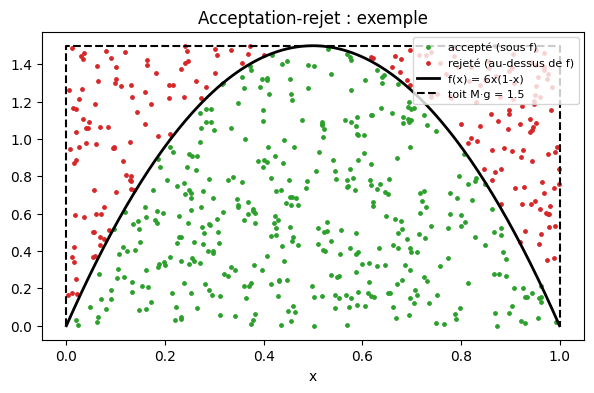

Proportion acceptée : 0.662   (théorie 1/M = 0.667)


In [2]:
# Illustration : f(x) = 6x(1-x) sur [0,1] (exemple pédagogique), g uniforme (g = 1), M = max f/g = 1.5
f_ex = lambda x: 6 * x * (1 - x)
M_ex = 1.5
n = 600
X = np.random.rand(n) # X ~ g (uniforme)
U = np.random.rand(n) # U ~ U[0,1]
h = U * M_ex # hauteur du tir : U * M g(X)
acc = h <= f_ex(X)

xx = np.linspace(0, 1, 200)
plt.figure(figsize=(7, 4))
plt.scatter(X[acc], h[acc], s=6, c="tab:green", label="accepté (sous f)")
plt.scatter(X[~acc], h[~acc], s=6, c="tab:red", label="rejeté (au-dessus de f)")
plt.plot(xx, f_ex(xx), "k", lw=2, label="f(x) = 6x(1-x)")
plt.plot([0, 0, 1, 1], [0, M_ex, M_ex, 0], "k--", label="toit M·g = 1.5")
plt.legend(loc="upper right", fontsize=8); plt.xlabel("x"); plt.title("Acceptation-rejet : exemple")
plt.show()
print(f"Proportion acceptée : {acc.mean():.3f}   (théorie 1/M = {1/M_ex:.3f})")

---
## Question 1 — Montrer que $M \ge 1$

**Rappel :** $f$ et $g$ sont des densités, l'aire sous chaque courbe vaut 1 (probabilité de prendre une valeur quelconque = 100 %) :
$$\int_{-\infty}^{+\infty} f(x)\,dx = 1 \qquad \int_{-\infty}^{+\infty} g(x)\,dx = 1$$

On intègre l'inégalité $f(x) \le M g(x)$ sur $\mathbb{R}$ (si une courbe est partout au-dessus d'une autre, l'aire sous elle est plus grande) ; $M$ est une constante qu'on sort de l'intégrale :
$$1 = \int_{-\infty}^{+\infty} f(x)\,dx \;\le\; \int_{-\infty}^{+\infty} M\,g(x)\,dx = M\int_{-\infty}^{+\infty} g(x)\,dx = M$$
$$\boxed{M \ge 1}$$

*Interprétation : l'aire sous le toit ($M$) est au moins égale à l'aire sous $f$ (1). Si $M = 1$, alors $f = g$ : le toit colle exactement à $f$.*

---
## Question 2 — Peut-on générer une loi de Cauchy à partir de $\mathcal{N}(0,1)$ ?

- loi cible (Cauchy) : $f(x) = \dfrac{1}{\pi(1+x^2)}$ ;
- loi instrumentale ($\mathcal{N}(0,1)$) : $g(x) = \dfrac{1}{\sqrt{2\pi}}\,e^{-x^2/2}$.

**Condition :** il faut un toit au-dessus de $f$ **partout**, c'est-à-dire (on divise par $g(x) > 0$)
$$f(x) \le M\,g(x) \iff \frac{f(x)}{g(x)} \le M \quad \text{pour tout } x.$$
Le rapport $f(x)/g(x)$ dit **combien de fois $f$ est plus haute que $g$** au point $x$ = le $M$ nécessaire en ce point.

**Calcul du rapport :**
$$
\begin{aligned}
\frac{f(x)}{g(x)} &= \frac{1}{\pi(1+x^2)} \cdot \frac{\sqrt{2\pi}}{e^{-x^2/2}} && \text{(diviser par une fraction = multiplier par l'inverse)} \\
&= \frac{\sqrt{2\pi}}{\pi}\cdot\frac{e^{x^2/2}}{1+x^2} && \text{(}1/e^{-a} = e^{a}\text{, on regroupe constantes et termes en } x\text{)} \\
&= \sqrt{\frac{2}{\pi}}\cdot\frac{e^{x^2/2}}{1+x^2} && \left(\tfrac{\sqrt{2}\sqrt{\pi}}{\sqrt\pi\sqrt\pi} = \tfrac{\sqrt2}{\sqrt\pi}\right)
\end{aligned}
$$
*Vérification en $x = 0$ : $\sqrt{2/\pi} \approx 0.80$.*

**Quand $x \to \pm\infty$ :** l'exponentielle $e^{x^2/2}$ croît beaucoup plus vite que le polynôme $1 + x^2$ :
$$\frac{f(x)}{g(x)} \xrightarrow[x\to\pm\infty]{} +\infty$$

**Conclusion :** le $M$ nécessaire change avec $x$ (c'est normal, on prend alors le plus grand), mais ici il **augmente sans limite** : il n'existe **aucune constante $M$** valable pour tous les $x$. **Réponse : non.**

**Intuition :** la loi de Cauchy a des queues **lourdes** (décroissance en $1/x^2$), la normale des queues **légères** ($e^{-x^2/2}$). Loin du centre, $g$ ne tire presque jamais de points alors que $f$ en demande encore : l'algorithme peut rejeter des points, pas en créer. *Règle : $g$ doit avoir des queues au moins aussi lourdes que $f$.* (L'inverse est possible : $\mathcal{N}(0,1)$ à partir de Cauchy, avec $M = \sqrt{2\pi/e} \approx 1.52$.)

*Remarque : cela ne veut pas dire que Cauchy est impossible à générer, seulement pas avec $g = \mathcal{N}(0,1)$ (par inversion : $X = \tan(\pi(U - 1/2))$).*

x =  0   f(x) = 0.31831   g(x) = 3.989e-01   f/g = M nécessaire : 7.979e-01
x =  1   f(x) = 0.15915   g(x) = 2.420e-01   f/g = M nécessaire : 6.577e-01
x =  2   f(x) = 0.06366   g(x) = 5.399e-02   f/g = M nécessaire : 1.179e+00
x =  3   f(x) = 0.03183   g(x) = 4.432e-03   f/g = M nécessaire : 7.182e+00
x =  4   f(x) = 0.01872   g(x) = 1.338e-04   f/g = M nécessaire : 1.399e+02
x =  5   f(x) = 0.01224   g(x) = 1.487e-06   f/g = M nécessaire : 8.235e+03
x =  6   f(x) = 0.00860   g(x) = 6.076e-09   f/g = M nécessaire : 1.416e+06
x =  7   f(x) = 0.00637   g(x) = 9.135e-12   f/g = M nécessaire : 6.969e+08
x =  8   f(x) = 0.00490   g(x) = 5.052e-15   f/g = M nécessaire : 9.693e+11
x =  9   f(x) = 0.00388   g(x) = 1.028e-18   f/g = M nécessaire : 3.776e+15
x = 10   f(x) = 0.00315   g(x) = 7.695e-23   f/g = M nécessaire : 4.096e+19


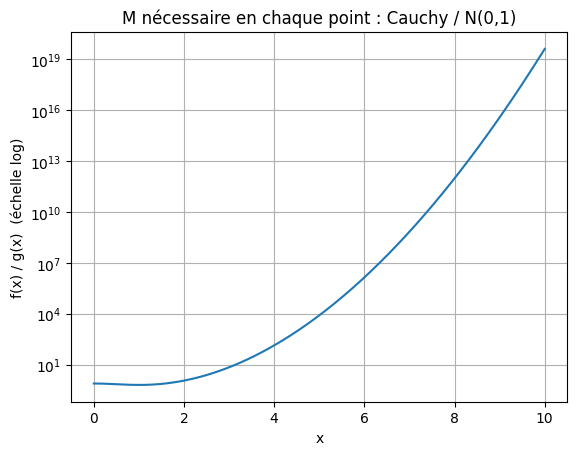

In [3]:
def f_cauchy(x):
    return 1 / (np.pi * (1 + x**2))

def g_normale(x):
    return np.exp(-x**2 / 2) / np.sqrt(2 * np.pi)

for x in range(0, 11):
    print(f"x = {x:2d}   f(x) = {f_cauchy(x):.5f}   g(x) = {g_normale(x):.3e}   f/g = M nécessaire : {f_cauchy(x)/g_normale(x):.3e}")

x = np.linspace(0, 10, 200)
plt.semilogy(x, f_cauchy(x) / g_normale(x))
plt.xlabel("x"); plt.ylabel("f(x) / g(x)  (échelle log)")
plt.title("M nécessaire en chaque point : Cauchy / N(0,1)")
plt.grid(True, which="both"); plt.show()

**Commentaire.** Le rapport $f/g$, c'est-à-dire le $M$ nécessaire en chaque point, augmente sans limite : $\approx 7$ en $x = 3$, plus de $8\,000$ en $x = 5$, environ $4\cdot 10^{19}$ en $x = 10$. Il n'existe donc pas de $M$ valable partout : la méthode ne peut pas fonctionner avec $g = \mathcal{N}(0,1)$.

---
## Question 3 — La méthode fournit bien la loi de densité $f$

**Notations :** un tir $= (X, U)$ avec $X \sim g$, $U \sim \mathcal{U}[0,1]$ indépendants ; les tirs successifs sont indépendants. Tir **accepté** : $U \le \frac{f(X)}{Mg(X)}$ ; **rejeté** : $U > \frac{f(X)}{Mg(X)}$. Ici $y$ est un **seuil quelconque sur l'axe horizontal** (pour comparer les fonctions de répartition en tout point).

### (a) Justification de l'égalité

$\{Y \le y\}$ se réalise si, pour un certain $i \ge 0$, les **$i$ premiers tirs sont rejetés** puis le **$(i+1)$-ème est accepté avec $X \le y$**.
- tirs **indépendants** $\Rightarrow$ on **multiplie** les probabilités ;
- cas $i = 0, 1, 2, \dots$ **disjoints** $\Rightarrow$ on **additionne** :
$$P(Y \le y) = \sum_{i=0}^{+\infty} P\!\left(X \le y,\ U \le \frac{f(X)}{Mg(X)}\right)\left[P\!\left(U \ge \frac{f(X)}{Mg(X)}\right)\right]^i$$

### (b) $P\!\left(X \le y,\ U \le \frac{f(X)}{Mg(X)}\right) = \frac1M F_f(y)$

*(coquille dans l'énoncé : il manque le signe « = » ; $F_f(y) = \int_{-\infty}^y f(t)\,dt$ est la fonction de répartition de $f$, définie dans l'énoncé)*

**Étape 1 — tir tombé en $x$ fixé.** $f(x), g(x)$ sont des nombres ; seul $U$ est aléatoire. Avec $a = \frac{f(x)}{Mg(x)} \in [0,1]$ et $P(U \le a) = a$ :
$$P(\text{accepté} \mid X = x) = \frac{f(x)}{M\,g(x)}$$

**Étape 2 — tous les $x \le y$.** Petit morceau de largeur $dx$ autour de $x$ : $X$ y tombe avec probabilité $g(x)\,dx$, puis est accepté avec probabilité $\frac{f(x)}{Mg(x)}$ (on **multiplie**) ; les morceaux sont disjoints (on **additionne** $\to$ intégrale) :
$$P\!\left(X \le y,\ U \le \frac{f(X)}{Mg(X)}\right) = \int_{-\infty}^{y} g(x)\cdot\frac{f(x)}{M\,g(x)}\,dx$$

**Étape 3 — simplification** ($g$ se simplifie, $M$ sort de l'intégrale, on reconnaît $F_f$) :
$$\int_{-\infty}^{y} \frac{f(x)}{M}\,dx = \frac1M\int_{-\infty}^{y} f(x)\,dx = \boxed{\frac{1}{M}\,F_f(y)}$$

*Pourquoi $g$ disparaît : là où $g$ est grande, les tirs tombent souvent mais le toit est haut (on accepte rarement) ; là où $g$ est petite, c'est l'inverse. Les deux effets se compensent.*

**Conséquence** ($y \to +\infty$, $F_f(+\infty) = 1$) :
$$P(\text{acceptation}) = \frac{1}{M}, \qquad q = P(\text{rejet}) = 1 - \frac{1}{M}$$

### (c) Conclusion : $P(Y \le y) = F_f(y)$

On remplace dans (a), puis on sort $F_f(y)/M$ de la somme (il ne dépend pas de $i$) :
$$P(Y \le y) = \sum_{i=0}^{+\infty} \frac{F_f(y)}{M}\, q^i = \frac{F_f(y)}{M}\sum_{i=0}^{+\infty} q^i$$
**Série géométrique** ($0 \le q < 1$) : $\displaystyle\sum_{i=0}^{+\infty} q^i = \frac{1}{1-q}$, avec $1 - q = \frac1M$ :
$$\sum_{i=0}^{+\infty} q^i = M \qquad\Longrightarrow\qquad P(Y \le y) = \frac{F_f(y)}{M}\cdot M = \boxed{F_f(y)}$$

Vrai pour **tout** $y$ : **$Y$ suit bien la loi de densité $f$.** $M$ disparaît : il influence le **nombre de tirs** (Q4), pas la **loi** de $Y$.

---
## Question 4 — Probabilité d'acceptation et nombre moyen de passages

**Probabilité d'acceptation** (Q3(b) avec $y \to +\infty$) :
$$p = \frac{1}{M}, \qquad q = 1 - \frac1M \qquad \text{(aire sous } f = 1\text{, aire sous le toit} = M\text{)}$$

**Nombre moyen de passages.** Soit $N$ le nombre de passages jusqu'à la première acceptation, et $E[N]$ son **espérance** (nombre moyen de passages si on répète l'algorithme un grand nombre de fois). On raisonne sur le **premier passage** : il est toujours effectué (1 passage) ; avec probabilité $p$ on s'arrête ; avec probabilité $q$ on recommence dans la même situation (passages indépendants) :
$$E[N] = 1 + q\,E[N] \;\Longrightarrow\; E[N](1-q) = 1 \;\Longrightarrow\; \boxed{E[N] = \frac{1}{1-q} = M}$$

*Exemple : $M = 4$ : on accepte 1 tir sur 4, il faut en moyenne 4 passages.*

**Conséquence pour le choix de $g$.** Il faut en moyenne $M$ passages par valeur : on veut **$M$ le plus petit possible** ($M \ge 1$, Q1). On choisit $g$ **de forme proche de $f$** (queues comprises, cf. Q2) pour que le toit colle à $f$. Le cas idéal $M = 1$ correspond à $g = f$, mais alors la méthode est inutile.

In [4]:
# Vérification sur l'exemple f(x) = 6x(1-x), g = 1, M = 1.5 : nombre moyen de passages ≈ M
def un_tir_exemple():
    n = 0
    while True:
        n += 1
        X, U = np.random.rand(), np.random.rand()
        if U <= f_ex(X) / (M_ex * 1):
            return X, n

N_ex = [un_tir_exemple()[1] for _ in range(10000)]
print(f"Nombre moyen de passages : {np.mean(N_ex):.3f}   (théorie M = {M_ex})")

Nombre moyen de passages : 1.516   (théorie M = 1.5)


---
## Question 5 — Application : gaussienne $\mathcal{N}(0,1)$ tronquée à gauche en $s$

On ne garde de la cloche $\mathcal{N}(0,1)$ que les valeurs $\ge s$ ; la queue restante est « étirée » pour que son aire vaille 1.

**Fonction erfc** (aire d'une queue gaussienne, pas de primitive simple ; `scipy.special.erfc`) :
$$\mathrm{erfc}(x) = \frac{2}{\sqrt{\pi}}\int_x^{\infty} e^{-u^2}\,du \quad\Longleftrightarrow\quad \int_x^{\infty} e^{-u^2}\,du = \frac{\sqrt\pi}{2}\,\mathrm{erfc}(x)$$

### (a) Première méthode : $X \sim \mathcal{N}(0,1)$ ; si $X \ge s$ accepter, sinon recommencer

Densité obtenue : $f(y) = \alpha\,\mathbf{1}_{y\ge s}\,e^{-y^2/2}$ (cloche mise à zéro à gauche de $s$, étirée par $\alpha$).

**(i) Constante $\alpha$.** $f$ est une densité (aire 1), et l'indicatrice vaut 0 à gauche de $s$ :
$$\alpha\int_{s}^{+\infty} e^{-y^2/2}\,dy = 1 \quad\Longrightarrow\quad \alpha = \frac{1}{\text{aire de la queue}}$$

Changement de variable $u = y/\sqrt2$ (pour avoir $e^{-u^2}$ ; car $u^2 = y^2/2$) — on change trois choses :
- exposant : $e^{-y^2/2} = e^{-u^2}$ ; bornes : $y = s \to u = s/\sqrt2$, $y = \infty \to u = \infty$ ; pas : $y = \sqrt2\,u \Rightarrow dy = \sqrt2\,du$.
$$\int_{s}^{+\infty} e^{-y^2/2}\,dy = \sqrt2\int_{s/\sqrt2}^{+\infty} e^{-u^2}\,du = \sqrt2\cdot\frac{\sqrt\pi}{2}\,\mathrm{erfc}\!\left(\frac{s}{\sqrt2}\right) = \sqrt{\frac{\pi}{2}}\,\mathrm{erfc}\!\left(\frac{s}{\sqrt2}\right)$$
$$\boxed{\alpha = \sqrt{\frac{2}{\pi}}\cdot\frac{1}{\mathrm{erfc}(s/\sqrt2)}}$$
*Vérification $s = 0$ : $\mathrm{erfc}(0) = 1$, $\alpha = \sqrt{2/\pi} = 2\times\frac{1}{\sqrt{2\pi}}$ : la demi-cloche est étirée d'un facteur 2. Pour $s = -\infty$ on retrouve l'aire totale $\sqrt{2\pi}$, d'où le $1/\sqrt{2\pi}$ de $\mathcal{N}(0,1)$.*

**(ii) Probabilité d'acceptation et nombre moyen de passages.** On accepte si $X \ge s$, avec la vraie densité $\mathcal{N}(0,1)$ :
$$P(\text{acceptation}) = \frac{1}{\sqrt{2\pi}}\int_{s}^{+\infty} e^{-y^2/2}\,dy = \frac{1}{\sqrt{2\pi}}\cdot\sqrt{\frac{\pi}{2}}\,\mathrm{erfc}\!\left(\frac{s}{\sqrt2}\right) = \frac12\,\mathrm{erfc}\!\left(\frac{s}{\sqrt2}\right) = M_1^{-1}$$
*($\sqrt{\pi/2}\cdot 1/\sqrt{2\pi} = \sqrt{1/4} = 1/2$)*. D'après Q4 : $E[N] = M_1 = \dfrac{2}{\mathrm{erfc}(s/\sqrt2)}$.

In [5]:
for s in [0, 1, 2, 3, 4]:
    p = 0.5 * erfc(s / np.sqrt(2))
    print(f"s = {s} :  P(acceptation) = {p:.6f}   M1 = {1/p:,.1f}")

s = 0 :  P(acceptation) = 0.500000   M1 = 2.0
s = 1 :  P(acceptation) = 0.158655   M1 = 6.3
s = 2 :  P(acceptation) = 0.022750   M1 = 44.0
s = 3 :  P(acceptation) = 0.001350   M1 = 740.8
s = 4 :  P(acceptation) = 0.000032   M1 = 31,574.4


**Commentaire.** Pour $s$ grand, la queue est très fine : presque tous les tirs sont rejetés et $M_1$ explose ($\approx 44$ pour $s = 2$, plus de $30\,000$ pour $s = 4$). La première méthode devient très lente.

### (b) Acceptation-rejet avec une exponentielle décalée

*Coquille dans l'énoncé : $g(x) = \mathbf{1}_{x\ge s}\,\lambda\,e^{-\lambda(x-s)}$ (un « = » en trop).* Idée : une loi instrumentale qui ne vit qu'à droite de $s$ et décroît comme la queue de la gaussienne.

**(i) Génération.** $X = s - \lambda^{-1}\ln U = s + E$ avec $E = -\frac{\ln U}{\lambda} \sim \mathcal{E}(\lambda)$ (inversion du Sujet 1, car $1 - U \sim \mathcal{U}[0,1]$ aussi : on « retourne » le segment). $X$ est une exponentielle **décalée de $s$** ($X \ge s$). Pour $x \ge s$ :
$$P(X > x) = P(E > x - s) = e^{-\lambda(x-s)} \;\Rightarrow\; F_X(x) = 1 - e^{-\lambda(x-s)} \;\Rightarrow\; g(x) = F_X'(x) = \lambda e^{-\lambda(x-s)}$$
*(la densité est la dérivée de la fonction de répartition ; pour $x < s$, $F_X = 0$)* $\;\Rightarrow\; \boxed{g(x) = \mathbf{1}_{x\ge s}\,\lambda e^{-\lambda(x-s)}}$

**(ii) Majoration de $f/g$.** Pour $x \ge s$, avec $e^a/e^b = e^{a-b}$ :
$$\frac{f(x)}{g(x)} = \frac{\alpha\,e^{-x^2/2}}{\lambda\,e^{-\lambda(x-s)}} = \frac{\alpha}{\lambda}\,e^{\,h(x) - \lambda s}, \qquad h(x) = -\frac{x^2}{2} + \lambda x$$
L'exponentielle est croissante : $f/g$ est maximal quand $h$ l'est. $h'(x) = -x + \lambda = 0 \iff x = \lambda$ ($h$ croît avant, décroît après), et $h(\lambda) = -\frac{\lambda^2}{2} + \lambda^2 = \frac{\lambda^2}{2}$. Donc $h(x) \le \frac{\lambda^2}{2}$ et
$$\boxed{\frac{f(x)}{g(x)} \le M_2 = \frac{\alpha}{\lambda}\,\exp\!\left(\frac{\lambda^2}{2} - \lambda s\right)}$$
*Contrairement à Q2 le rapport est borné : l'exponentielle a une queue plus lourde que la gaussienne.*

**(iii) Choix optimal de $\lambda$.** On minimise $M_2(\lambda)$ ; comme $\ln$ est croissante, on minimise $\varphi(\lambda) = \ln M_2 = \ln\alpha - \ln\lambda + \frac{\lambda^2}{2} - \lambda s$ (l'exponentielle disparaît) :
$$\varphi'(\lambda) = -\frac1\lambda + \lambda - s = 0 \;\overset{\times\lambda}{\iff}\; \lambda^2 - s\lambda - 1 = 0 \;\iff\; \lambda = \frac{s \pm \sqrt{s^2+4}}{2}$$
$\lambda > 0$ et $\sqrt{s^2+4} > s$ : on garde le signe +.
$$\boxed{\lambda^* = \frac{s + \sqrt{s^2+4}}{2}}$$
*Minimum car $M_2 \to +\infty$ quand $\lambda \to 0$ ($-\ln\lambda$) et quand $\lambda \to \infty$ ($\lambda^2/2$).*

Avec $\lambda^{*2} = s\lambda^* + 1$ (équation ci-dessus) :
$$\frac{\lambda^{*2}}{2} - \lambda^* s = \frac{s\lambda^*+1}{2} - \frac{2\lambda^* s}{2} = \frac{1 - \lambda^* s}{2}$$
d'où
$$\boxed{M_2^* = \frac{\alpha}{\lambda^*}\,\exp\!\left(\frac{1 - \lambda^* s}{2}\right)}$$

### (c) Comparaison des deux méthodes

**(i) Comparaison de $M_1$ et $M_2^*$.**
$$M_1 = \frac{2}{\mathrm{erfc}(s/\sqrt2)} \qquad\qquad M_2^* = \frac{\alpha}{\lambda^*}\exp\!\left(\frac{1-\lambda^* s}{2}\right)$$
Pour $s$ grand, $P(X \ge s) \to 0$ donc $M_1 \to +\infty$, alors que l'exponentielle décalée suit la queue de $f$ et $M_2^*$ reste proche de 1. On estime numériquement le seuil où les courbes se croisent.

s = -1 :  M1 =      1.189   M2* = 1.723
s =  0 :  M1 =      2.000   M2* = 1.315
s =  1 :  M1 =      6.303   M2* = 1.141
s =  2 :  M1 =     43.956   M2* = 1.071
s =  3 :  M1 =    740.797   M2* = 1.041
s =  4 :  M1 =  31574.386   M2* = 1.026

Seuil (M1 = M2*) : s ≈ -0.47


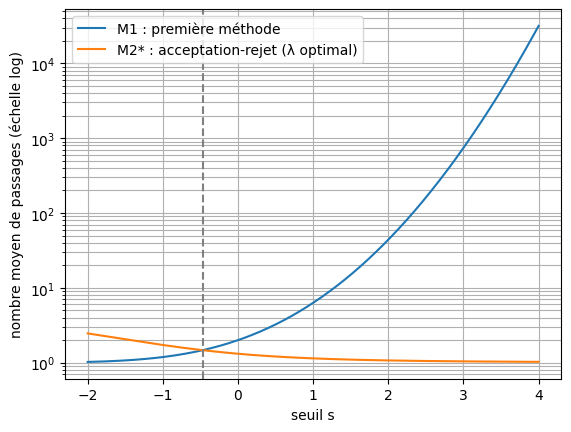

In [6]:
def M1(s):
    return 2 / erfc(s / np.sqrt(2))

def M2(s):
    lam = (s + np.sqrt(s**2 + 4)) / 2 # λ* optimal
    alpha = np.sqrt(2 / np.pi) / erfc(s / np.sqrt(2))
    return alpha / lam * np.exp((1 - lam * s) / 2)

for s in [-1, 0, 1, 2, 3, 4]:
    print(f"s = {s:2d} :  M1 = {M1(s):>10.3f}   M2* = {M2(s):.3f}")

s_grille = np.linspace(-2, 4, 2001)
idx = np.argmin(np.abs(M1(s_grille) - M2(s_grille)))
print(f"\nSeuil (M1 = M2*) : s ≈ {s_grille[idx]:.2f}")

plt.semilogy(s_grille, M1(s_grille), label="M1 : première méthode")
plt.semilogy(s_grille, M2(s_grille), label="M2* : acceptation-rejet (λ optimal)")
plt.axvline(s_grille[idx], color="gray", ls="--")
plt.xlabel("seuil s"); plt.ylabel("nombre moyen de passages (échelle log)")
plt.legend(); plt.grid(True, which="both"); plt.show()

**Commentaire.** $M_1$ croît très vite avec $s$ (échelle log), alors que $M_2^*$ reste proche de 1 ($\approx 1.14$ pour $s = 1$, $\approx 1.03$ pour $s = 4$). Les courbes se croisent en $s \approx -0.4$ : au-delà, la méthode d'acceptation-rejet est préférable ; pour $s$ très négatif on garde presque toute la cloche, $M_1 -> 1$ et la première méthode est meilleure.

**(ii) Simulation.** Choix **$s = 1$** : taux d'acceptation correct pour les deux méthodes ($1/M_1 \approx 0.16$, $1/M_2^* \approx 0.88$). On génère $T = 10\,000$ valeurs avec chaque méthode en comptant les passages. Attendu : $M_1 \approx 6.30$, $\lambda^* = \frac{1+\sqrt5}{2} \approx 1.62$, $M_2^* \approx 1.14$.

In [7]:
s = 1
T = 10000

lam = (s + np.sqrt(s**2 + 4)) / 2                  
alpha = np.sqrt(2 / np.pi) / erfc(s / np.sqrt(2)) 
M1_th = M1(s)
M2_th = M2(s)

def f(x):# densité cible : gaussienne tronquée (x >= s)
    return alpha * np.exp(-x**2 / 2)

def g(x):# densité instrumentale : exponentielle décalée
    return lam * np.exp(-lam * (x - s))

def methode1():
    n = 0
    while True:
        n += 1
        X = np.random.randn() # X ~ N(0,1)
        if X >= s:
            return X, n

def methode2():
    n = 0
    while True:
        n += 1
        X = s - np.log(np.random.rand()) / lam  #X ~ g  
        U = np.random.rand()
        if U <= f(X) / (M2_th * g(X)):            
            return X, n

Y1 = np.zeros(T); N1 = np.zeros(T)
Y2 = np.zeros(T); N2 = np.zeros(T)
for k in range(T):
    Y1[k], N1[k] = methode1()
    Y2[k], N2[k] = methode2()

print(f"λ* = {lam:.4f}")
print(f"Méthode 1 : passages moyens = {np.mean(N1):.3f}   théorie M1  = {M1_th:.3f}")
print(f"Méthode 2 : passages moyens = {np.mean(N2):.3f}   théorie M2* = {M2_th:.3f}")
print(f"Moyennes des échantillons : {np.mean(Y1):.3f} et {np.mean(Y2):.3f}   (théorie φ(s)/P(X≥s) = {np.exp(-s**2/2)/np.sqrt(2*np.pi)/(0.5*erfc(s/np.sqrt(2))):.3f})")

λ* = 1.6180
Méthode 1 : passages moyens = 6.310   théorie M1  = 6.303
Méthode 2 : passages moyens = 1.139   théorie M2* = 1.141
Moyennes des échantillons : 1.529 et 1.528   (théorie φ(s)/P(X≥s) = 1.525)


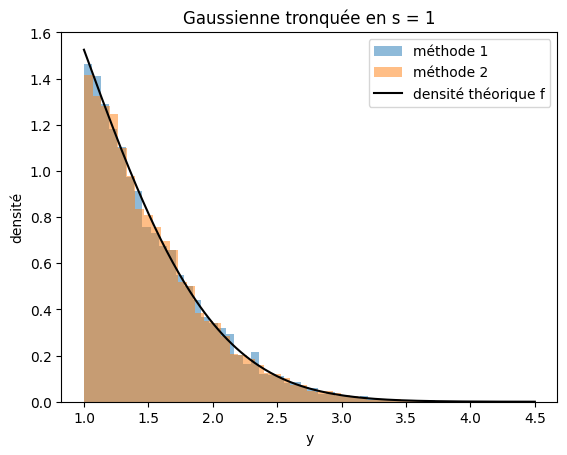

In [8]:
y = np.linspace(s, 4.5, 300)
plt.hist(Y1, bins=50, density=True, alpha=0.5, label="méthode 1")
plt.hist(Y2, bins=50, density=True, alpha=0.5, label="méthode 2")
plt.plot(y, f(y), "k", label="densité théorique f")
plt.xlabel("y"); plt.ylabel("densité")
plt.title("Gaussienne tronquée en s = 1")
plt.legend(); plt.show()

**Commentaire.** Le nombre moyen de passages est cohérent avec la théorie : $\approx 6.31$ pour la méthode 1 ($M_1 \approx 6.30$) et $\approx 1.14$ pour la méthode 2 ($M_2^* \approx 1.14$). Les deux histogrammes commencent en $s = 1$ et suivent la même densité théorique $f$ : les deux méthodes génèrent la même loi (moyennes $\approx 1.53$ pour les deux, théorie $1.525$), mais l'acceptation-rejet avec l'exponentielle décalée demande environ 5.5 fois moins de passages.

---
## Conclusion

- La méthode d'**acceptation-rejet** génère n'importe quelle densité $f$ à partir d'une loi $g$ qu'on sait générer, dès qu'il existe $M$ avec $f \le Mg$ ; elle est **exacte** (Q3) et coûte en moyenne **$M$ passages** (Q4).
- Le choix de $g$ est crucial : queues au moins aussi lourdes que $f$ (sinon impossible, Q2) et forme proche de $f$ (pour $M$ proche de 1).
- Pour la gaussienne tronquée, la méthode naïve devient inutilisable pour $s$ grand ($M_1$ explose) ; l'exponentielle décalée avec $\lambda^*$ optimal garde $M_2^* \approx 1$.

---
## Fiche de révision — notions à savoir expliquer à l'oral

| Notion | À dire en une phrase |
|---|---|
| Principe | Tirer des points sous le toit $Mg$, garder ceux sous $f$ ; $X \sim g$ (horizontal), $U$ uniforme (vertical). |
| Test d'acceptation | $U \le f(X)/(Mg(X))$ : rapport des hauteurs de $f$ et du toit en $X$. |
| Choix de $M$ | $M = \max f/g$ ; il faut que ce maximum existe (rapport borné). |
| $M \ge 1$ | Aire sous $f$ = 1, aire sous le toit = $M$. |
| Cauchy / normale | $f/g \to \infty$ : queues de $g$ trop légères, pas de toit possible. |
| Preuve (Q3) | $i$ rejets puis acceptation ; $g$ se simplifie ; série géométrique $= M$ ; on obtient $F_f$. |
| Coût (Q4) | Proba d'acceptation $1/M$, nombre moyen de passages $M$ ; choisir $g$ proche de $f$. |
| Gaussienne tronquée | Méthode naïve $M_1 = 2/\mathrm{erfc}(s/\sqrt2)$ ; exponentielle décalée, $\lambda^* = (s+\sqrt{s^2+4})/2$, $M_2^* \approx 1$. |
| Outils de calcul | Changement de variable (3 choses changent : expression, bornes, pas) ; extremum par dérivée nulle ; $\ln$ croissant pour simplifier. |